# IT2011 – Artificial Intelligence and Machine Learning
## King County House Price Prediction — Extra Trees Regressor
### Combined Group Preprocessing Pipeline Version (Leakage-Safe)

**Individual model:** Extra Trees Regressor  
**Problem type:** Regression  
**Target:** `price`

This notebook trains the Extra Trees model using the **corrected outputs of the combined group preprocessing pipeline**. The group pipeline already performed the train–test split before fitting learned preprocessing, so the supplied training and testing CSV files must remain separate.

> **Important:** This notebook does **not** combine or re-split the two CSV files, and it does **not** fit another scaler or encoder. This preserves the held-out test set for final evaluation.


In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Validation and model utilities
from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone

# Model
from sklearn.ensemble import ExtraTreesRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# General settings
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

print('Libraries imported successfully!')
print('Random state:', RANDOM_STATE)


Libraries imported successfully!
Random state: 42


## 1. Load the Corrected Combined-Pipeline Outputs

Upload the two CSV files produced by the corrected group pipeline:

- `final_train_processed_house_data.csv`
- `final_test_processed_house_data.csv`

These files are already separated into training and testing sets. Therefore, **no new `train_test_split()` is performed here**.


In [2]:
# Upload the corrected train and test CSV files in Google Colab
from google.colab import files

print('Upload final_train_processed_house_data.csv and final_test_processed_house_data.csv')
uploaded = files.upload()


Upload final_train_processed_house_data.csv and final_test_processed_house_data.csv


Saving final_test_processed_house_data.csv to final_test_processed_house_data.csv
Saving final_train_processed_house_data.csv to final_train_processed_house_data.csv


In [3]:
# Load the already-separated outputs of the corrected combined pipeline
TRAIN_FILE = 'final_train_processed_house_data.csv'
TEST_FILE = 'final_test_processed_house_data.csv'

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

print('Corrected combined-pipeline datasets loaded successfully!')
print('Training shape:', train_df.shape)
print('Testing shape :', test_df.shape)

print('\nSame columns in train and test:', list(train_df.columns) == list(test_df.columns))
print('Target column present:', 'price' in train_df.columns and 'price' in test_df.columns)


Corrected combined-pipeline datasets loaded successfully!
Training shape: (17290, 93)
Testing shape : (4323, 93)

Same columns in train and test: True
Target column present: True


## 2. Validate the Processed Data

The corrected combined pipeline has already performed feature engineering, log transformations, train-fitted scaling, and zipcode one-hot encoding. This section only validates the supplied model-ready datasets; it does not learn any additional preprocessing parameters.


In [4]:
# Basic validation before modeling
print('Training missing values:', train_df.isnull().sum().sum())
print('Testing missing values :', test_df.isnull().sum().sum())
print('Training duplicate rows:', train_df.duplicated().sum())
print('Testing duplicate rows :', test_df.duplicated().sum())

print('\nTraining data types:')
print(train_df.dtypes.value_counts())

print('\nFirst five training rows:')
display(train_df.head())


Training missing values: 0
Testing missing values : 0
Training duplicate rows: 2
Testing duplicate rows : 0

Training data types:
float64    84
int64       9
Name: count, dtype: int64

First five training rows:


,bedrooms,bathrooms,floors,waterfront,view,condition,grade,sqft_basement,yr_built,lat,...,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,price
0,-0.395263,-0.474451,-0.919600,0,0,4,9,-0.656310,0.404001,-1.396608,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,325000.0
1,-1.468964,-1.452583,-0.919600,0,0,3,6,-0.200433,-1.430565,-0.060172,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,257000.0
2,-0.395263,-1.452583,0.001545,0,0,3,6,-0.451165,-0.988910,-0.552847,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,228500.0
3,-0.395263,0.177636,-0.919600,0,0,4,7,1.189993,0.200160,-1.193614,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,288000.0
4,-1.468964,0.503680,0.922690,0,0,3,8,0.016109,1.219364,1.040039,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,479000.0


## 3. Define Training and Testing Inputs

`price` is separated as the target. Every other column is used as a predictor. Because the group pipeline already created the split, `X_train`/`y_train` come directly from the training CSV and `X_test`/`y_test` come directly from the held-out testing CSV.


In [5]:
# Separate predictors and target WITHOUT re-splitting the data
TARGET = 'price'

X_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].copy()

X_test = test_df.drop(columns=[TARGET]).copy()
y_test = test_df[TARGET].copy()

# Keep test columns in exactly the same order as training columns
X_test = X_test.reindex(columns=X_train.columns)

print('Model inputs prepared successfully!')
print('X_train:', X_train.shape)
print('y_train:', y_train.shape)
print('X_test :', X_test.shape)
print('y_test :', y_test.shape)
print('\nFeature columns aligned:', list(X_train.columns) == list(X_test.columns))
print('All predictors numeric:', X_train.select_dtypes(exclude=np.number).shape[1] == 0)


Model inputs prepared successfully!
X_train: (17290, 92)
y_train: (17290,)
X_test : (4323, 92)
y_test : (4323,)

Feature columns aligned: True
All predictors numeric: True


## 3A. Exploratory Data Analysis (Training Set Only)

The histogram below shows the distribution of house prices in the **training set**. The test data is intentionally excluded from EDA so it remains held out. The scatterplot shows the relationship between house price and a numerical training predictor, if available.


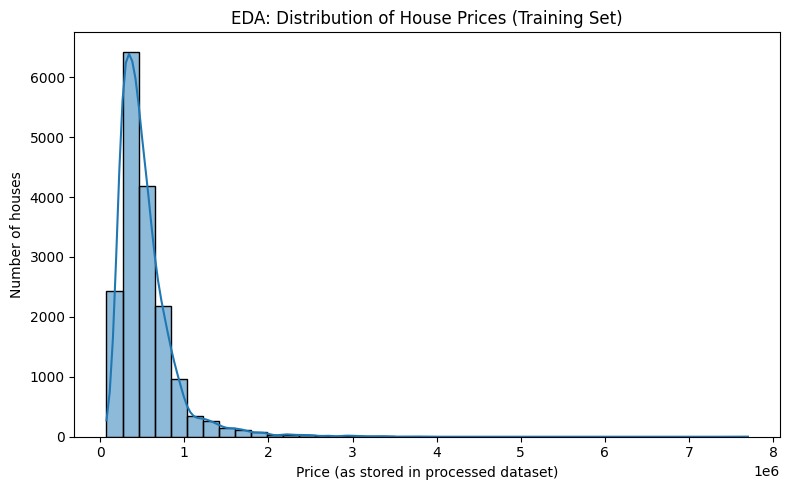

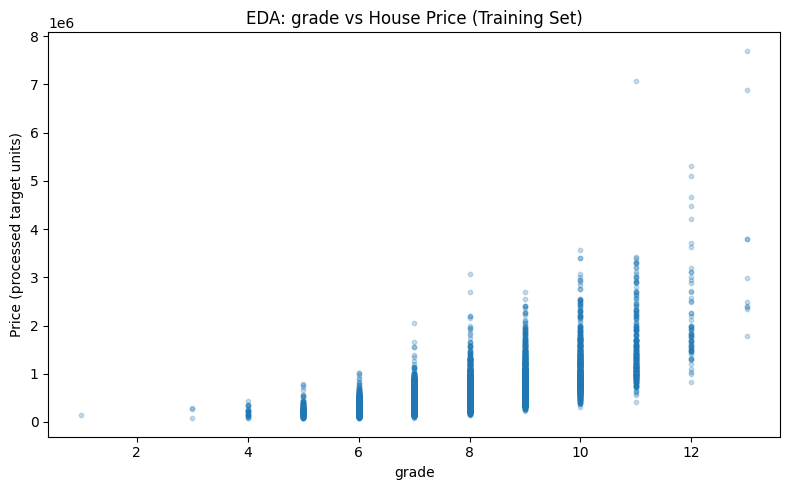

In [6]:
# EDA visualization 1: target distribution (training data only)
plt.figure(figsize=(8, 5))
sns.histplot(train_df['price'].dropna(), bins=40, kde=True)
plt.title('EDA: Distribution of House Prices (Training Set)')
plt.xlabel('Price (as stored in processed dataset)')
plt.ylabel('Number of houses')
plt.tight_layout()
plt.show()

# EDA visualization 2: price vs one numerical feature (training only)
eda_features = [c for c in X_train.select_dtypes(include=np.number).columns if c != 'price']
preferred = next((c for c in ['sqft_living', 'grade', 'sqft_above'] if c in eda_features), None)
eda_feature = preferred or (eda_features[0] if eda_features else None)
if eda_feature:
    plt.figure(figsize=(8, 5))
    plt.scatter(X_train[eda_feature], y_train, alpha=0.25, s=10)
    plt.title(f'EDA: {eda_feature} vs House Price (Training Set)')
    plt.xlabel(eda_feature)
    plt.ylabel('Price (processed target units)')
    plt.tight_layout()
    plt.show()
else:
    print('No numeric predictor available for a scatterplot.')


## 4. Baseline + Four Hyperparameter-Tuned Variants

The baseline uses default Extra Trees model hyperparameters (except reproducibility and parallelism settings). Four additional configurations change different hyperparameters. All five models use the **same training data** and identical 5-fold CV. The test set is not used for model selection.


In [7]:
# One default baseline + FOUR separately tuned configurations
variants = {
    'Baseline - Default Extra Trees': ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=1),
    'V1 - More trees': ExtraTreesRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    'V2 - Limited depth': ExtraTreesRegressor(n_estimators=150, max_depth=20, random_state=RANDOM_STATE, n_jobs=1),
    'V3 - Leaf and split regularization': ExtraTreesRegressor(n_estimators=150, min_samples_leaf=2, min_samples_split=5, random_state=RANDOM_STATE, n_jobs=1),
    'V4 - Combined tuning': ExtraTreesRegressor(n_estimators=200, max_depth=25, min_samples_leaf=2, min_samples_split=4, max_features=0.7, random_state=RANDOM_STATE, n_jobs=1)
}
params_to_show = ['n_estimators', 'max_depth', 'min_samples_leaf', 'min_samples_split', 'max_features']
parameter_table = pd.DataFrame([{'Model': name, **{p: model.get_params()[p] for p in params_to_show}} for name, model in variants.items()])
display(parameter_table)


,Model,n_estimators,max_depth,min_samples_leaf,min_samples_split,max_features
0,Baseline - Default Extra Trees,100,NaN,1,2,1.0
1,V1 - More trees,300,NaN,1,2,1.0
2,V2 - Limited depth,150,20.0,1,2,1.0
3,V3 - Leaf and split regularization,150,NaN,2,5,1.0
4,V4 - Combined tuning,200,25.0,2,4,0.7


## 5. Training-Only Cross-Validation: Baseline vs Four Tuned Variants

Use the same 5 shuffled folds for all configurations. **Lowest CV MAE wins**. RMSE and R² provide supporting comparisons. These are four manually selected hyperparameter configurations, not four independent randomized/grid searches.


In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
cv_rows = []
for name, model in variants.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1,
                            return_train_score=True)
    cv_rows.append({'Model': name, 'CV MAE': -scores['test_MAE'].mean(),
                    'CV MAE Std': scores['test_MAE'].std(),
                    'CV RMSE': -scores['test_RMSE'].mean(),
                    'CV R2': scores['test_R2'].mean(),
                    'CV Train MAE': -scores['train_MAE'].mean()})
    print('Completed:', name)
comparison = pd.DataFrame(cv_rows).sort_values('CV MAE').reset_index(drop=True)
display(comparison.round(4))

Completed: Baseline - Default Extra Trees
Completed: V1 - More trees
Completed: V2 - Limited depth
Completed: V3 - Leaf and split regularization
Completed: V4 - Combined tuning


,Model,CV MAE,CV MAE Std,CV RMSE,CV R2,CV Train MAE
0,V1 - More trees,65669.7474,2079.2225,120316.9792,0.8889,0.0343
1,V3 - Leaf and split regularization,65965.4066,2265.4297,123537.3938,0.8831,18143.0042
2,Baseline - Default Extra Trees,66046.6896,2224.1605,120742.2423,0.8881,0.0457
3,V4 - Combined tuning,66223.2924,2401.2055,124040.8597,0.8822,20046.2196
4,V2 - Limited depth,66535.9023,2156.7073,121569.7589,0.8866,16474.2281


## 6. Select the Best of Five Models and Evaluate Once on Held-Out Test Set

The baseline and four tuned configurations are eligible. Select using **training CV MAE only**, then fit on the full training set and evaluate once on the untouched test set.


In [9]:
selected_name = comparison.iloc[0]['Model']
final_model = clone(variants[selected_name])
final_X_train, final_X_test = X_train, X_test
final_model.fit(final_X_train, y_train)
print('Selected:', selected_name)
print('Selection criterion: lowest 5-fold training CV MAE')
print('Selected parameters:', final_model.get_params())

Selected: V1 - More trees
Selection criterion: lowest 5-fold training CV MAE
Selected parameters: {'bootstrap': False, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': 1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [10]:
# FINAL EVALUATION ON THE HELD-OUT TEST SET
y_pred_final = final_model.predict(final_X_test)

final_mae = mean_absolute_error(y_test, y_pred_final)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
final_r2 = r2_score(y_test, y_pred_final)

print('Final Extra Trees Test Evaluation')
print('---------------------------------')
print('Selected Model :', selected_name)
print('MAE            :', round(final_mae, 2))
print('RMSE           :', round(final_rmse, 2))
print('R²             :', round(final_r2, 4))


Final Extra Trees Test Evaluation
---------------------------------
Selected Model : V1 - More trees
MAE            : 69427.57
RMSE           : 145522.1
R²             : 0.8599


## 7. Model Interpretation


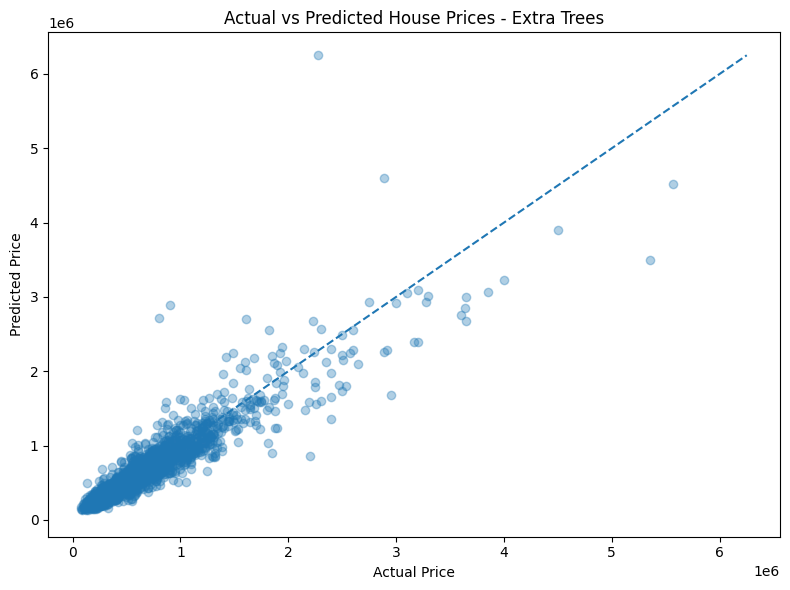

In [11]:
# Actual vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_final, alpha=0.35)

low = min(y_test.min(), y_pred_final.min())
high = max(y_test.max(), y_pred_final.max())
plt.plot([low, high], [low, high], '--')

plt.title('Actual vs Predicted House Prices - Extra Trees')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.tight_layout()
plt.show()


Top 15 most important features:


,Feature,Importance
0,grade,0.225644
1,sqft_living_log,0.183914
2,lat,0.118306
3,sqft_above_log,0.063797
4,sqft_living15,0.062695
5,bathrooms,0.046922
6,view,0.036584
7,waterfront,0.036490
8,zipcode_98004,0.028468
9,long,0.025204


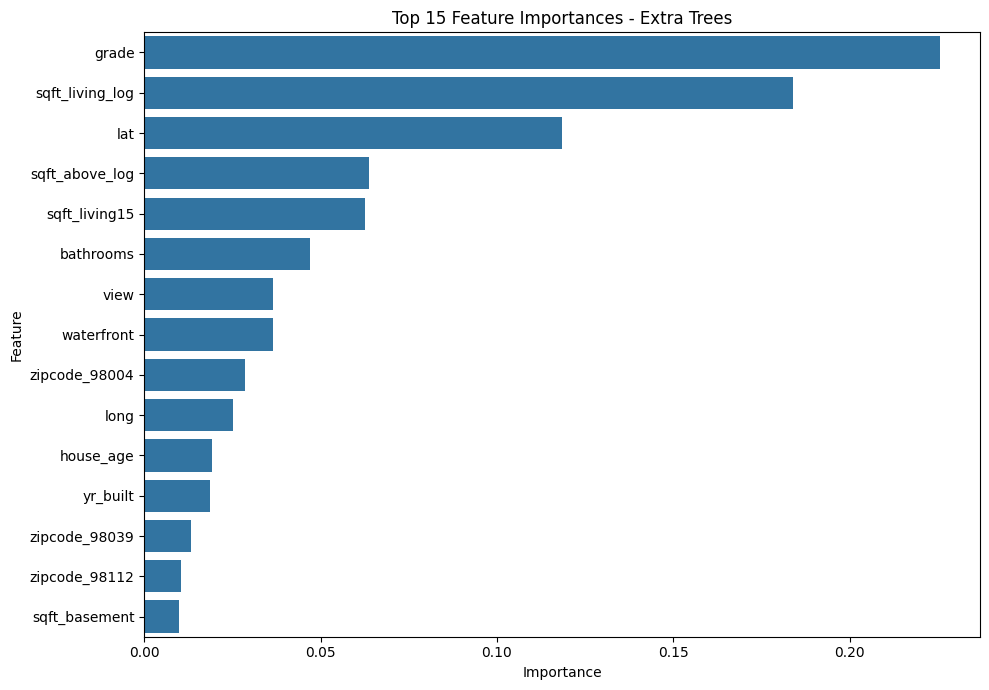

In [12]:
# Feature importance from the selected final Extra Trees model
feature_importance = pd.DataFrame({
    'Feature': final_X_train.columns,
    'Importance': final_model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print('Top 15 most important features:')
display(feature_importance.head(15))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)
plt.title('Top 15 Feature Importances - Extra Trees')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


Final Extra Trees Variety Comparison:


,Model,CV MAE,CV MAE Std,CV RMSE,CV R2,CV Train MAE
0,V1 - More trees,65669.75,2079.222520,120316.98,0.8889,0.034317
1,V3 - Leaf and split regularization,65965.41,2265.429694,123537.39,0.8831,18143.004241
2,Baseline - Default Extra Trees,66046.69,2224.160507,120742.24,0.8881,0.045691
3,V4 - Combined tuning,66223.29,2401.205516,124040.86,0.8822,20046.219559
4,V2 - Limited depth,66535.90,2156.707272,121569.76,0.8866,16474.228067


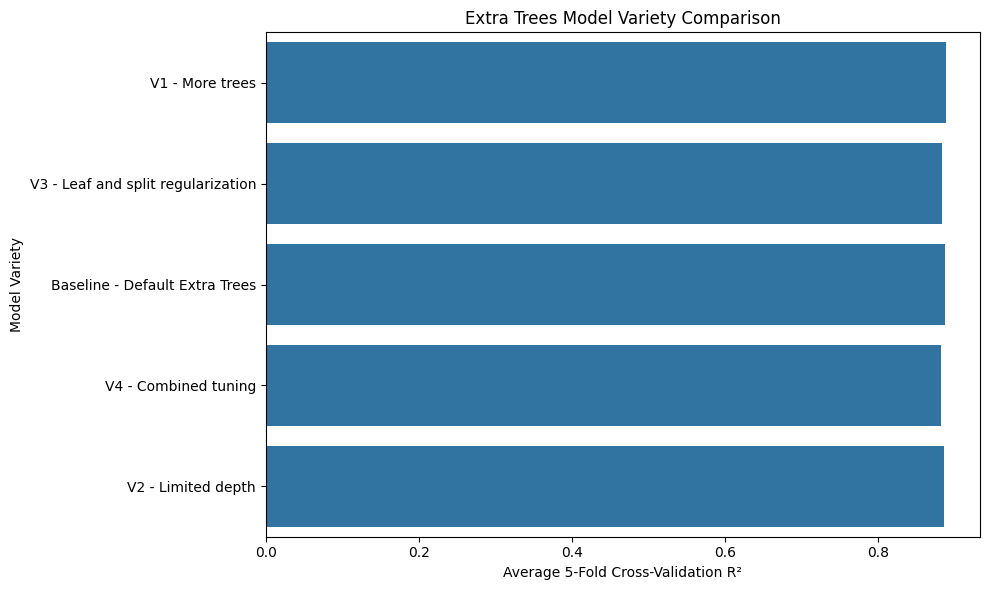

In [13]:
# Visual comparison of model varieties using CV R²
final_comparison = comparison.copy()
final_comparison['CV MAE'] = final_comparison['CV MAE'].round(2)
final_comparison['CV RMSE'] = final_comparison['CV RMSE'].round(2)
final_comparison['CV R2'] = final_comparison['CV R2'].round(4)

print('Final Extra Trees Variety Comparison:')
display(final_comparison)

plt.figure(figsize=(10, 6))
sns.barplot(data=final_comparison, x='CV R2', y='Model')
plt.title('Extra Trees Model Variety Comparison')
plt.xlabel('Average 5-Fold Cross-Validation R²')
plt.ylabel('Model Variety')
plt.tight_layout()
plt.show()


## 8. Overfitting / Underfitting Check

Training and testing performance are compared for the selected final model. A large gap between training and testing performance may indicate overfitting.


In [14]:
# Compare final model performance on training and testing data
y_pred_train = final_model.predict(final_X_train)

train_mae = mean_absolute_error(y_train, y_pred_train)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
train_r2 = r2_score(y_train, y_pred_train)

fit_check = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'MAE': [train_mae, final_mae],
    'RMSE': [train_rmse, final_rmse],
    'R²': [train_r2, final_r2]
})

print('Training vs Testing Performance:')
display(fit_check.round(4))


Training vs Testing Performance:


,Dataset,MAE,RMSE,R²
0,Training,0.0135,0.8963,1.0000
1,Testing,69427.5672,145522.1043,0.8599


## Additional preprocessing variety: engineered-feature ablation (training CV only)

To demonstrate a **different preprocessing setup** independently of hyperparameter tuning, compare the selected Extra Trees configuration with all available features against the same configuration after excluding engineered columns, **if those columns are present**. This is a feature-set ablation, not a new algorithm or a fifth tuned variant. It does **not** refit the group preprocessing pipeline and does **not** claim that removing features is always beneficial.

Both feature sets are compared using identical 5-fold CV on training rows only. The main selected model and its held-out test score remain unchanged. If no named engineered features are found, the comparison is explicitly skipped rather than inventing a result.


In [15]:
engineered_candidates = [
    'sale_year', 'sale_month', 'house_age', 'years_since_renovation',
    'sqft_living_ratio', 'sqft_basement_ratio', 'sqft_living_per_floor',
    'age', 'renovated', 'is_renovated'
]
engineered_present = [c for c in engineered_candidates if c in X_train.columns]
print('Recognized engineered features:', engineered_present)
if engineered_present and X_train.shape[1] > len(engineered_present):
    ablation_rows = []
    for feature_set, x_data in [
        ('All combined-pipeline features', X_train),
        ('Without recognized engineered features', X_train.drop(columns=engineered_present))
    ]:
        result = cross_validate(clone(variants[selected_name]), x_data, y_train,
                                cv=cv, scoring=scoring, n_jobs=-1)
        ablation_rows.append({'Preprocessing setup': feature_set,
                             'Number of features': x_data.shape[1],
                             'CV MAE': -result['test_MAE'].mean(),
                             'CV RMSE': -result['test_RMSE'].mean(),
                             'CV R2': result['test_R2'].mean()})
    ablation_comparison = pd.DataFrame(ablation_rows)
    display(ablation_comparison.round(4))
    print('Lower CV MAE indicates better performance in this feature-set comparison.')
else:
    ablation_comparison = None
    print('Ablation skipped: no recognized engineered columns (or no remaining predictors).')
    print('For a valid preprocessing comparison, provide the group feature-engineering column names.')


Recognized engineered features: ['sale_year', 'sale_month', 'house_age']


,Preprocessing setup,Number of features,CV MAE,CV RMSE,CV R2
0,All combined-pipeline features,92,65669.7474,120316.9792,0.8889
1,Without recognized engineered features,89,66602.0287,121185.7524,0.8873


Lower CV MAE indicates better performance in this feature-set comparison.


## Viva demonstration: predict one unseen input row

Use the first held-out row only as a **demonstration after evaluation**. The feature order matches training. The output is in the same target units as the processed `price` column (which may be transformed); do not label it as currency unless you have confirmed that the target is in original currency units.


In [16]:
demo_row = final_X_test.iloc[[0]]
demo_prediction = final_model.predict(demo_row)[0]
print('Chosen model:', selected_name)
print('Prediction (processed target units):', round(float(demo_prediction), 4))
print('Actual (processed target units):', round(float(y_test.iloc[0]), 4))
print('Input feature count:', demo_row.shape[1])
print('First few input features:')
display(demo_row.iloc[:, :min(8, demo_row.shape[1])])


Chosen model: V1 - More trees
Prediction (processed target units): 385235.8633
Actual (processed target units): 365000.0
Input feature count: 92
First few input features:


,bedrooms,bathrooms,floors,waterfront,view,condition,grade,sqft_basement
0,0.678437,0.177636,0.92269,0,0,4,8,-0.65631


## Dynamic conclusion: explain the actual results (after running)

The cell below summarizes the actual CV winner and test results instead of asserting in advance that any tuned variant must win. It also checks the CV train/validation MAE gap, which can indicate overfitting.


In [17]:
baseline_mae = float(comparison.loc[comparison['Model'] == 'Baseline - Default Extra Trees', 'CV MAE'].iloc[0])
selected_cv_mae = float(comparison.iloc[0]['CV MAE'])
selected_cv_train_mae = float(comparison.iloc[0]['CV Train MAE'])
print('FINAL PRESENTATION SUMMARY')
print('Baseline + four manually tuned Extra Trees configurations were compared.')
print('Best CV model:', selected_name)
print(f'Baseline CV MAE: {baseline_mae:,.4f}')
print(f'Winner CV MAE: {selected_cv_mae:,.4f}')
print(f'CV improvement over baseline: {baseline_mae - selected_cv_mae:,.4f} (positive means better)')
print(f'CV train vs validation MAE gap: {selected_cv_mae - selected_cv_train_mae:,.4f}')
print(f'Final test: MAE={final_mae:,.4f}, RMSE={final_rmse:,.4f}, R²={final_r2:.4f}')
if selected_cv_mae - selected_cv_train_mae > 0.25 * max(abs(selected_cv_mae), 1e-9):
    print('Interpretation: sizable training-to-validation error gap; investigate overfitting.')
else:
    print('Interpretation: no large relative CV training-to-validation MAE gap by this heuristic.')
if ablation_comparison is not None:
    best_preprocess = ablation_comparison.sort_values('CV MAE').iloc[0]['Preprocessing setup']
    print('Secondary feature-set ablation favors:', best_preprocess)
print('Caution: compare actual metrics; no model is guaranteed to outperform baseline.')


FINAL PRESENTATION SUMMARY
Baseline + four manually tuned Extra Trees configurations were compared.
Best CV model: V1 - More trees
Baseline CV MAE: 66,046.6896
Winner CV MAE: 65,669.7474
CV improvement over baseline: 376.9422 (positive means better)
CV train vs validation MAE gap: 65,669.7131
Final test: MAE=69,427.5672, RMSE=145,522.1043, R²=0.8599
Interpretation: sizable training-to-validation error gap; investigate overfitting.
Secondary feature-set ablation favors: All combined-pipeline features
Caution: compare actual metrics; no model is guaranteed to outperform baseline.


## Limitations and suggested improvements

- **CV leakage caveat:** The group CSVs are already preprocessed. Even if their train/test split was leakage-safe, any imputer, scaler, encoder, selector or other learned transform fitted on *all training rows* before KFold can leak information across CV folds. The rigorous fix is to start with preprocessed-independent raw training rows and fit learned transformations **inside** a scikit-learn `Pipeline` for each fold. These CSVs alone cannot guarantee fully leakage-free cross-validation.
- **Target units:** Check whether `price` was log-transformed or standardized. If so, MAE/RMSE and the example prediction are on the transformed scale until correctly inverse-transformed.
- **Hyperparameter search scope:** Four manually chosen alternatives are a limited search; a properly nested `RandomizedSearchCV` or `GridSearchCV` could explore more combinations.
- **Feature ablation:** The named-column removal experiment is only valid for engineered features that actually exist. It is not a comparison of separately refitted encoders/scalers.
- **Generalization:** A single held-out split may not capture time or geographical distribution shifts; consider temporal/geographic validation when appropriate.
- **Further improvements:** Verify pipeline provenance and feature engineering, tune with a compute budget, examine residuals by price band, and compare against a simple regression baseline.


